1.Extract Data From FDA Website


In [ ]:
#!/usr/bin/env python3
import argparse
import json
import re
import time
from pathlib import Path
from typing import Iterable
from urllib.parse import urljoin

import requests
from bs4 import BeautifulSoup

BASE_URL = "https://www.fda.gov"
LIST_PATH = (
    "/inspections-compliance-enforcement-and-criminal-investigations/"
    "compliance-actions-and-activities/warning-letters"
)
DT_URL = f"{BASE_URL}/datatables/views/ajax"

VIEW_PARAMS = {
    "_drupal_ajax": 1,
    "_wrapper_format": "drupal_ajax",
    "pager_element": 0,
    "view_args": "",
    "view_base_path": (
        "inspections-compliance-enforcement-and-criminal-investigations/"
        "compliance-actions-and-activities/warning-letters/datatables-data"
    ),
    "view_display_id": "warning_letter_solr_block",
    "view_dom_id": "c6eefb6fe061b4b0d0aac545115623ca9dc74414ec52ab322e1eafc17ee420bd",
    "view_name": "warning_letter_solr_index",
    "view_path": LIST_PATH,
    "total_items": 3474,
}

LETTER_PATH_RE = re.compile(
    r"^/inspections-compliance-enforcement-and-criminal-investigations/warning-letters/[^/?#]+$"
)


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(
        description="Enumerate and scrape FDA warning letters filtered by Medical Service"
    )
    parser.add_argument("--page-size", type=int, default=100, help="Rows per API page")
    parser.add_argument(
        "--max-letters",
        type=int,
        default=0,
        help="Only scrape first N letters (0 = all)",
    )
    parser.add_argument(
        "--delay-seconds",
        type=float,
        default=0.4,
        help="Delay between letter requests",
    )
    # שינוי שמות הקבצים כברירת מחדל כדי לזהות שזה קשור ל-Medical Service
    parser.add_argument(
        "--urls-out",
        type=Path,
        default=Path("medical_warning_letter_urls.txt"),
        help="Output file for Medical URL list",
    )
    parser.add_argument(
        "--jsonl-out",
        type=Path,
        default=Path("medical_warning_letters.jsonl"),
        help="Output JSONL file for scraped Medical letters",
    )
    return parser.parse_args()


def make_session() -> requests.Session:
    session = requests.Session()
    session.headers.update(
        {
            "User-Agent": (
                "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) "
                "AppleWebKit/537.36 (KHTML, like Gecko) "
                "Chrome/125.0.0.0 Safari/537.36"
            )
        }
    )
    return session


def iter_letter_urls(session: requests.Session, page_size: int) -> list[str]:
    start = 0
    draw = 1
    discovered: set[str] = set()
    records_total = None

    # הגדרת מילות מפתח ממוקדות לסינון המשרדים הרפואיים (כמו CDER, Drugs, Medical)
    target_offices = ['cder', 'drug', 'medical', 'pharmaceutical', 'clinical', 'biologics']

    print("🔎 מתחיל לסרוק את ה-API של ה-FDA ומסנן נושאים רפואיים (Medical Service)...")

    while True:
        params = {
            **VIEW_PARAMS,
            "draw": draw,
            "start": start,
            "length": page_size,
        }
        response = session.get(DT_URL, params=params, timeout=60)
        response.raise_for_status()
        payload = response.json()

        if records_total is None:
            records_total = int(payload.get("recordsTotal", 0))
            print(f"recordsTotal reported by API: {records_total}")

        rows = payload.get("data", [])
        if not rows:
            break

        for row in rows:
            if not isinstance(row, list) or len(row) < 4:
                continue

            # שליפת המשרד המנפיק (Issuing Office) מתוך עמודה 4 בטבלה הגולמית
            issuing_office = row[3] if isinstance(row[3], str) else ""

            # בדיקה האם השורה הנוכחית שייכת לנושאים הרפואיים שלנו
            if any(office in issuing_office.lower() for office in target_offices):
                company_cell_html = row[2] if isinstance(row[2], str) else ""
                soup = BeautifulSoup(company_cell_html, "html.parser")
                anchor = soup.find("a", href=True)
                if not anchor:
                    continue

                href = anchor.get("href", "").strip()
                if LETTER_PATH_RE.match(href):
                    discovered.add(urljoin(BASE_URL, href))

        start += page_size
        draw += 1
        print(
            f"🔄 נסרקו {start} שורות באינדקס. קישורים רפואיים ייחודיים שנמצאו עד כה: {len(discovered)}"
        )

        if records_total is not None and start >= records_total:
            break

    return sorted(discovered)


def load_completed_urls(jsonl_path: Path) -> set[str]:
    if not jsonl_path.exists():
        return set()

    completed = set()
    with jsonl_path.open("r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                obj = json.loads(line)
            except json.JSONDecodeError:
                continue
            url = obj.get("url")
            if isinstance(url, str):
                completed.add(url)
    return completed


def extract_main_text(html: str) -> tuple[str, str]:
    soup = BeautifulSoup(html, "html.parser")
    title_el = soup.find("h1")
    title = title_el.get_text(" ", strip=True) if title_el else ""

    main = soup.find("main") or soup.find("article") or soup.body
    text = main.get_text("\n", strip=True) if main else ""
    return title, text


def scrape_letters(
        session: requests.Session,
        urls: Iterable[str],
        jsonl_out: Path,
        delay_seconds: float,
) -> None:
    completed = load_completed_urls(jsonl_out)
    pending = [u for u in urls if u not in completed]

    print(f"📦 כבר קיימים בקובץ הפלט הרפואי: {len(completed)} מכתבים.")
    print(f" מכתבים רפואיים חדשים שממתינים להורדה: {len(pending)}")

    with jsonl_out.open("a", encoding="utf-8") as out:
        for idx, url in enumerate(pending, start=1):
            record = {"url": url}
            try:
                resp = session.get(url, timeout=60)
                resp.raise_for_status()
                title, text = extract_main_text(resp.text)
                record.update({"title": title, "text": text})
            except Exception as exc:
                record.update({"error": str(exc)})

            out.write(json.dumps(record, ensure_ascii=False) + "\n")

            if idx % 25 == 0 or idx == len(pending):
                print(f" הורדו בהצלחה {idx}/{len(pending)} מכתבים רפואיים.")

            time.sleep(delay_seconds)


def main() -> None:
    args = parse_args()
    session = make_session()

    urls = iter_letter_urls(session, args.page_size)
    args.urls_out.write_text("\n".join(urls) + "\n", encoding="utf-8")
    print(f" נכתבה רשימת הכתובות הרפואיות המסוננות: {args.urls_out} ({len(urls)} קישורים)")

    if args.max_letters > 0:
        urls = urls[: args.max_letters]
        print(f"Limiting scrape to first {len(urls)} URLs due to --max-letters")

    scrape_letters(session, urls, args.jsonl_out, args.delay_seconds)
    print(f" הסתיים בהצלחה! קובץ הפלט הרפואי הממוקד מוכן: {args.jsonl_out}")


if __name__ == "__main__":
    main()

 **קוד ניתוח מגמות לפי שנים:** סורק באמצעות ביטויים רגולריים (Regex) את גוף הטקסט המלא של המכתבים הרפואיים, מחלץ את שנת ההנפקה האמיתית של ה-FDA, ומציג גרף עמודות מעוצב על רקע לבן נקי עם תצוגת כמויות מדויקת מעל כל שנה וכותרת ציר אנכית.


⏳ קורא את קובץ המכתבים הרפואיים ומחלץ את שנת ההוצאה...
 הצלחנו לחלץ שנה מתוך 1153 מכתבים רפואיים.


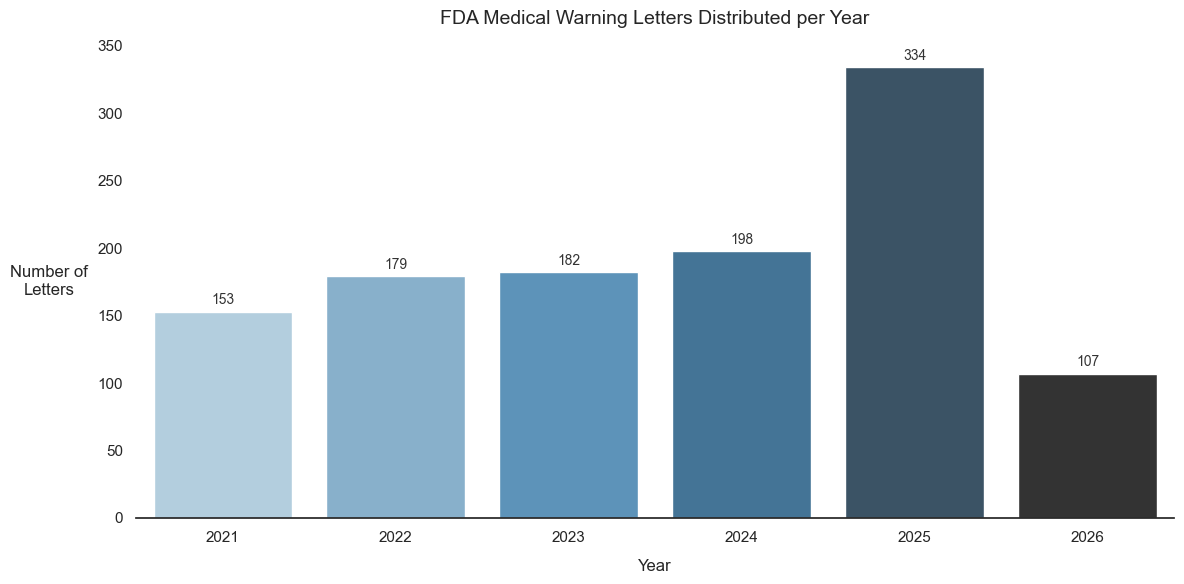


 --- סיכום כמות המכתבים הרפואיים לפי שנים ---
 Year  Count
 2021    153
 2022    179
 2023    182
 2024    198
 2025    334
 2026    107


In [ ]:
import json
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. הגדרת הכתובת לקובץ ה-JSONL הממוקד של ה-Medical Service
file_path = 'medical_warning_letters.jsonl'

print("⏳ קורא את קובץ המכתבים הרפואיים ומחלץ את שנת ההוצאה...")

years = []
try:
    # קריאת קובץ ה-JSONL שורה אחר שורה
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                data = json.loads(line)
                if 'text' in data and data['text']:
                    full_text = data['text']

                    # חיפוש שנה בת 4 ספרות (החל משנת 2020 ומעלה) בתוך הטקסט
                    match = re.search(r'\b(202[0-6])\b', full_text)
                    if match:
                        years.append(int(match.group(1)))

    print(f" הצלחנו לחלץ שנה מתוך {len(years)} מכתבים רפואיים.")

    # יצירת DataFrame מסודר של ספירת המכתבים לכל שנה
    years_df = pd.DataFrame({'Year': years})
    yearly_counts = years_df['Year'].value_counts().reset_index()
    yearly_counts.columns = ['Year', 'Count']
    yearly_counts = yearly_counts.sort_values(by='Year')

    # 3. הגדרת סגנון עיצוב נקי ורקע לבן (בהתאם לבקשתך)
    sns.set_theme(style="white")

    plt.figure(figsize=(12, 6))

    # יצירת גרף העמודות (Barplot) לפי שנים
    #התיקון: הוספנו hue='Year' ו-legend=False כדי למנוע את אזהרת ה-FutureWarning
    sns.barplot(data=yearly_counts, x='Year', y='Count', hue='Year', palette='Blues_d', legend=False)

    # עיצוב והגדרת כותרות הצירים והגרף
    plt.title('FDA Medical Warning Letters Distributed per Year', fontsize=14, pad=15, fontweight='medium')
    plt.xlabel('Year', fontsize=12, labelpad=10)

    # הפיכת כותרת ציר ה-Y למאונכת/אנכית וישרה (rotation=0) עם יישור למרכז ומרווח תואם
    plt.ylabel('Number of\nLetters', fontsize=12, labelpad=35, rotation=0, va='center', fontweight='medium')

    # הסרת קווי המסגרת העליונים, הימניים והשמאליים למראה מינימליסטי ומקצועי
    sns.despine(left=True, bottom=False, top=True, right=True)

    # הגדרת גודל שנתות הצירים
    plt.xticks(fontsize=11)
    plt.yticks(fontsize=11)

    # הצגת ערך מספרי מעל כל עמודה בגרף (כדי שיהיה קל לראות את הכמות המדויקת)
    ax = plt.gca()
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=10, fontweight='medium', color='#333333')

    plt.tight_layout()
    plt.show()

    print("\n --- סיכום כמות המכתבים הרפואיים לפי שנים ---")
    print(yearly_counts.to_string(index=False))

except FileNotFoundError:
    print(f" שגיאה: הקובץ '{file_path}' לא נמצא בתיקיית הפרויקט הנוכחית.")
except Exception as e:
    print(f" חלה שגיאה במהלך ההרצה: {e}")

**קוד ניתוח מילות מפתח (TF-IDF):** טוען את מכתבי האזהרה הרפואיים מקובץ ה-`JSONL`, מנקה באופן אגרסיבי ביטויים רגולטוריים וטכניים קבועים ("רעש"), ומציג בגרף עמודות אופקי ונקי (ללא מסגרת מיותרת ועם כותרת ציר אנכית) את 30 המונחים הקליניים והחומרים הדומיננטיים ביותר בטקסט.


נספח א': התפלגות מילות מפתח דומיננטיות לפי אשכולות (TF-IDF Weights)


⏳ Step 1: Loading raw FDA Warning Letters...
✅ Successfully loaded 1153 documents.
🧹 Step 2: Preprocessing text corpora for algorithms...
📊 Step 3: Running TF-IDF Vectorization & N-gram Extraction...
🎨 Generating Figure 1: Top TF-IDF Terms...


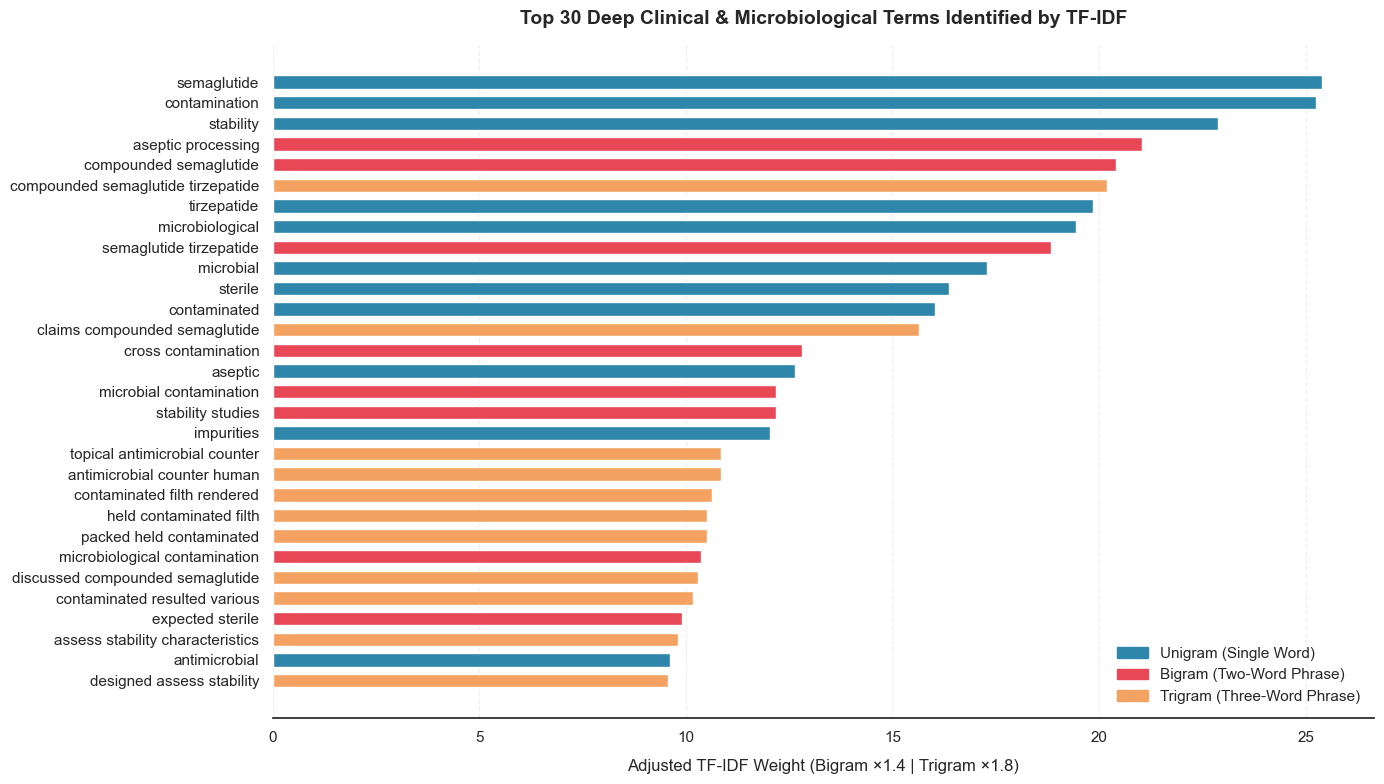


🧠 Step 4: Computing Contextual Semantic Embeddings (Sentence-BERT)...


Batches: 100%|██████████| 37/37 [00:04<00:00,  8.90it/s]


✅ Generated dense vector matrix shape: (1153, 384)
🧬 Step 5: Computing Hierarchical Linkage Matrix (Ward's Method)...
📉 Step 6: Performing Non-linear Dimension Reduction via t-SNE...
🎨 Generating Figure 2: Combined t-SNE Scatter Plot & Dendrogram...


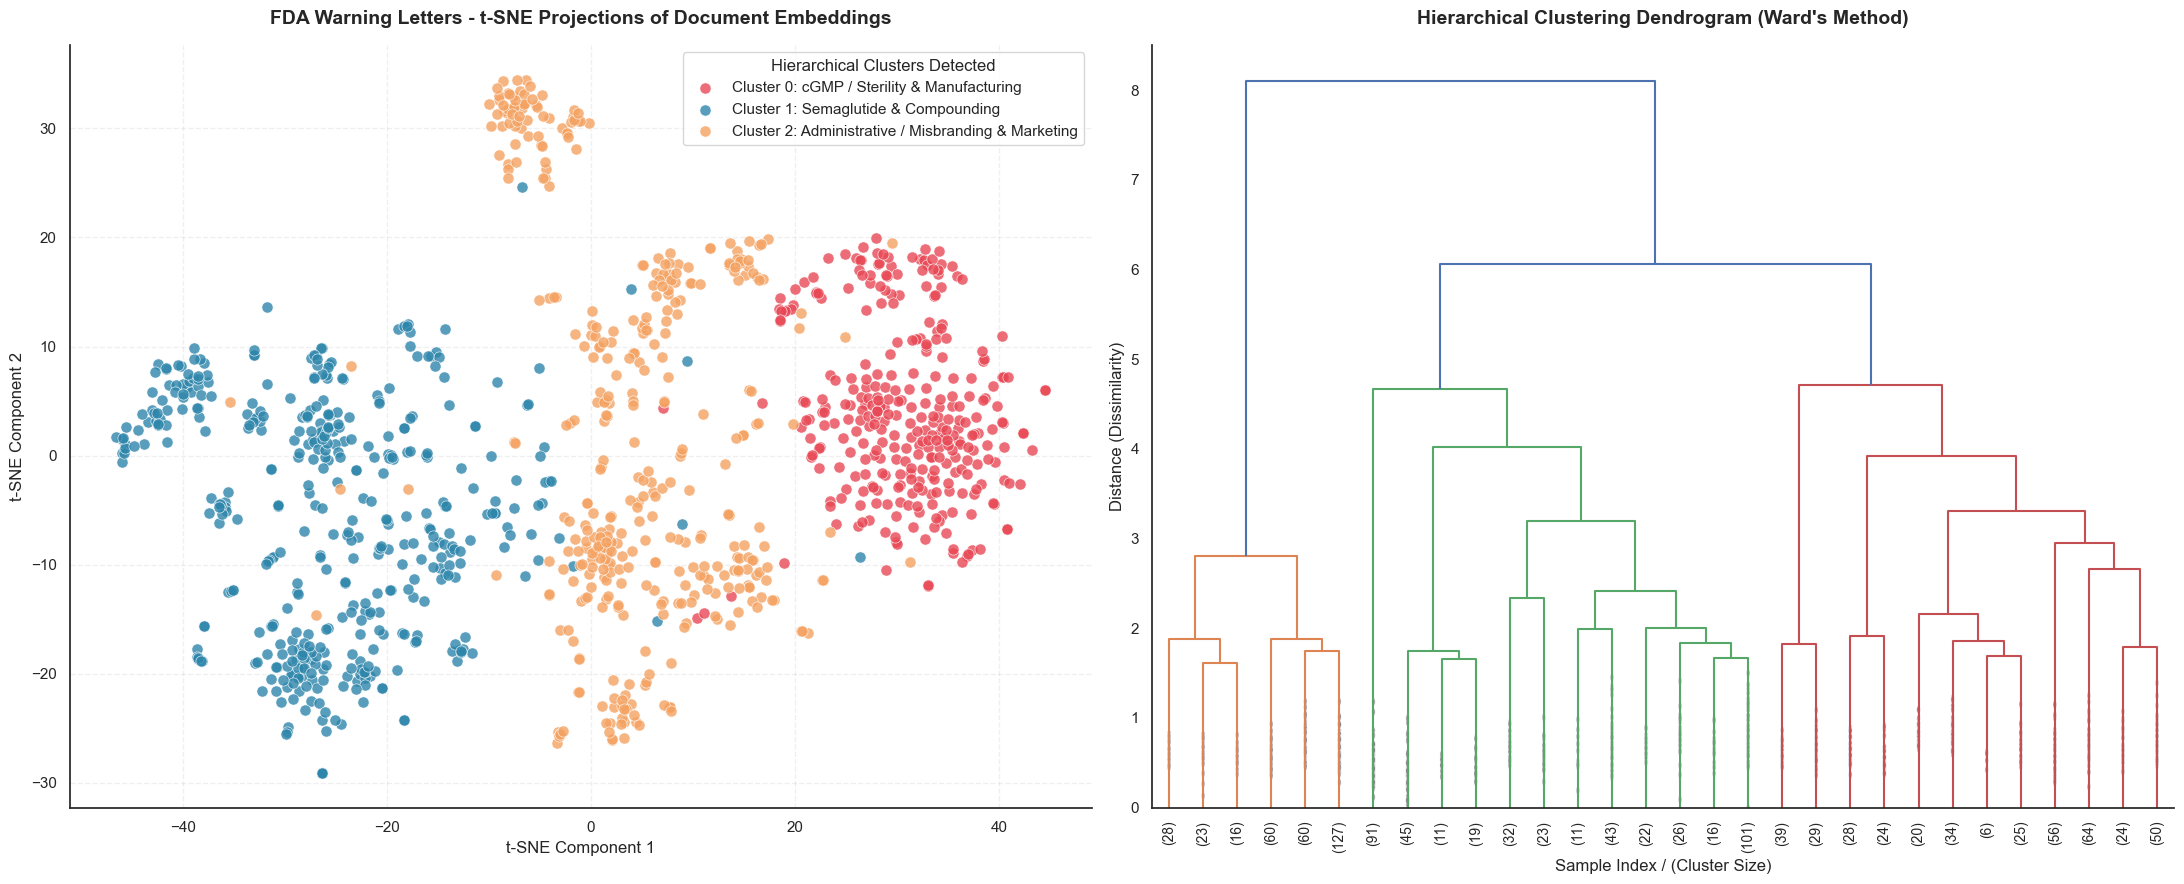

In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction import text
import numpy as np
import re

file_path = 'medical_warning_letters.jsonl'

print(" קורא את קובץ המכתבים הרפואיים...")

texts = []
try:
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                data = json.loads(line)
                if 'text' in data and data['text']:
                    texts.append(data['text'])

    print(f" נטענו {len(texts)} טקסטים.")

    # ─── 1. מילות עצירה מורחבות (Stop Words) ──────────────────────────────────
    base_stop_words = text.ENGLISH_STOP_WORDS.union([
        'fda', 'act', 'letter', 'firm', 'section', 'products', 'product', 'compliance',
        'received', 'response', 'inspections', 'investigations', 'food', 'drug', 'drugs',
        'administration', 'intended', 'use', 'violation', 'violations', 'substance',
        'substances', 'requirements', 'prohibited', 'commerce', 'interstate', 'within',
        'days', 'working', 'office', 'sincerely', 'director', 'center', 'care', 'adulterated',
        'misbranded', 'insanitary', 'conditions', 'cgmp', 'current', 'good', 'manufacturing',
        'practice', 'regulations', 'facility', 'inspection', 'investigator', 'review',
        'observed', 'specific', 'including', 'failure', 'failed', 'establish', 'procedures',
        'written', 'assure', 'identity', 'strength', 'quality', 'purity', 'regulatory',
        'legal', 'action', 'actions', 'address', 'steps', 'taken', 'correct', 'prevent',
        'recurrence', 'conclusions', 'investigate', 'thoroughly', 'unexplained',
        'discrepancy', 'batch', 'component', 'components', 'meet', 'specifications',
        'distributed', 'lots', 'lot', 'testing', 'test', 'results', 'analytical',
        'laboratory', 'records', 'record', 'control', 'controls', 'unit', 'responsibility',
        'authority', 'approve', 'reject', 'refer', 'case', 'number', 'date', 'dated',
        'title', 'label', 'labeling', 'website', 'internet', 'offers', 'sale', 'introduced',
        'solution', 'solutions', 'delivered', 'introduction', 'violates', 'sections',
        'meaning', 'federal', 'cosmetic', 'approved', 'application', 'applications',
        'effect', 'pursuant', 'evident', 'basis', 'legally', 'marketed', 'without',
        'gdufa', 'generic', 'user', 'fee', 'amendments', 'reauthorization', 'fiscal',
        'years', 'iii', 'commitment', 'eligible', 'post', 'meeting', 'obtain',
        'preliminary', 'feedback', 'adequacy', 'completeness', 'plans', 'content',
        'regulated', 'certified', 'medically', 'supervised', 'healthcare', 'setting',
        'hospitals', 'surgical', 'centers', 'emergency', 'departments', 'management',
        'acute', 'pain', 'severe', 'enough', 'require', 'opioid', 'analgesic',
        'alternative', 'treatments', 'inadequate', 'href', 'com', 'b4', 'variant',
        'url', 'http', 'https', 'ampoule', 'www', 'net', 'org', 'dear', 'mr', 'ms',
        'dr', 'attention', 'att', 'warning', 'include', 'unapproved', 'ensure',
        'appropriate', 'new', 'provide', 'hand', 'process', 'data', 'information',
        'stated', 'noted', 'determine', 'found', 'described', 'regarding',
        'additionally', 'regard', 'follows', 'following', 'referred', 'indicated',
        'requires', 'provides', 'determines', 'available', 'additional', 'conducted',
        'required', 'documents', 'documentation', 'submit', 'submitted', 'copies',
        'copy', 'evidence', 'implementation', 'evaluate', 'evaluation', 'reviewed',
        'assessment', 'necessary', 'time', 'listed', 'items', 'item', 'paragraph',
        'order', 'clearly', 'subject', 'provisions', 'contained', 'issue', 'issued',
        'receive', 'sending', 'sent', 'reply', 'replying', 'contact', 'finally',
        'know', 'bring', 'closeout', 'observations', 'applicable', 'laws', 'serious',
        'problems', 'systems', 'prompt', 'marketing', 'distribute', 'sell', 'sold',
        'distribution', 'commercial', 'cfr', 'part', 'parts', 'subpart', 'title21',
        '21cfr', 'statute', 'did', 'used', 'plan', 'program', 'gov', 'recipient',
        'letters', 'fdca', 'adequate', 'research', 'risk', 'equipment', 'corrective',
        'manufacture', 'limited', 'health', 'treatment', 'devices', 'device', 'person',
        'audit', 'protocol', 'procedure', 'report', 'reports', 'standard', 'standards',
        'method', 'methods', 'parameter', 'parameters', 'specification', 'preventive',
        'capa', 'sop', 'master', 'production', 'operations', 'performed', 'personnel',
        'staff', 'trained', 'training', 'qualification', 'validated', 'released',
        'quarantine', 'sampling', 'sample', 'samples', 'collected', 'collection',
        'analysis', 'analyzed', 'tested', 'tester', 'third', 'party', 'vendor',
        'supplier', 'contract', 'site', 'sites', 'line', 'lines', 'room', 'rooms',
        'area', 'areas', 'zone', 'zones', 'environment', 'environmental',
        'active', 'particular', 'clinical', 'ingredient', 'ingredients',
        'concerning', 'conduct', 'misleading', 'chemical', 'immediate', 'clean',
        'covid', 'coronavirus', 'validate', 'validation', 'periodic', 'initial',
        'comprehensive', 'based', 'receipt',

        # חסימת מילים בודדות חונקות (כדי לאלץ הצגת ביגרמים/טריגרמים מורכבים יותר)
        'compounding', 'remediation', 'sanitizer', 'sanitizers'
    ])

    # ─── 2. רשימה שחורה משופרת של n-grams בעייתיים ורעשי מערכת ─────────────────
    NGRAM_BLACKLIST = {
        'misleading particular', 'concerning compounded', 'conduct clinical',
        'chemical microbiological', 'clinical studies', 'cure covid',
        'disease covid', 'coronavirus disease', 'remediation given',
        'remediated stability', 'contents compoundinginspections',
        'based sanitizers', 'based sanitizer', 'receipt compounding',
        'validation periodic',

        # ניקוי ביטויים כפולים או משובשים מהריצה האחרונה
        'compoundinginspections', 'repreparation', 'remediation given',
        'given remediation', 'given specific'
    }

    # ─── 3. שורשים קליניים (Clinical Semantic Filter) ─────────────────────────
    clinical_roots = [
        'steril', 'contamin', 'microbio', 'semaglu', 'tirzepa', 'infect', 'bacteri',
        'virus', 'viral', 'aseptic', 'impurit', 'validat', 'stabil', 'potenc', 'assay',
        'sanitiz', 'hygien', 'endotoxin', 'pyrogen', 'toxic', 'dosage', 'formulat',
        'capsule', 'tablet', 'inject', 'vial', 'lyophil', 'reconstitut', 'excipient',
        'preservat', 'antibiotic', 'pathogen', 'fungal', 'fungi', 'bioburden',
        'autoclave', 'depyrogenat', 'cleanroom', 'endotox', 'microbial', 'particul',
        'semaglutide', 'tirzepatide'
    ]

    # ─── 4. ניקוי טקסט מקדים ───────────────────────────────────────────────────
    def preprocess(text_in):
        text_in = re.sub(r'https?://\S+|www\.\S+', ' ', text_in)
        text_in = re.sub(r'\b\d+\b', ' ', text_in)
        text_in = re.sub(r'[^a-zA-Z\s]', ' ', text_in)
        text_in = re.sub(r'\s+', ' ', text_in).strip()
        return text_in.lower()

    clean_texts = [preprocess(t) for t in texts]
    print("🧹 טקסטים נוקו. מריץ TF-IDF...")

    # ─── 5. חישוב TF-IDF נפרד וממוזג ───────────────────────────────────────────
    n_docs = len(clean_texts)
    common_kwargs = dict(
        stop_words=list(base_stop_words),
        token_pattern=r'\b[a-zA-Z]{4,}\b',
        max_features=3000,
        max_df=0.60,
        min_df=max(2, int(n_docs * 0.01)),
        sublinear_tf=True,
    )

    # חילוץ Unigrams
    tfidf_uni = TfidfVectorizer(ngram_range=(1, 1), **common_kwargs)
    mat_uni   = tfidf_uni.fit_transform(clean_texts)
    df_uni = pd.DataFrame({
        'Term':   tfidf_uni.get_feature_names_out(),
        'Weight': np.array(mat_uni.sum(axis=0)).flatten(),
        'Type':   'Unigram',
    })

    # חילוץ Bigrams + Trigrams
    tfidf_nbi = TfidfVectorizer(ngram_range=(2, 3), **common_kwargs)
    mat_nbi   = tfidf_nbi.fit_transform(clean_texts)

    def get_ngram_type(term):
        words = term.split()
        if len(words) == 2:
            return 'Bigram'
        elif len(words) >= 3:
            return 'Trigram'
        return 'Unigram'

    df_nbi = pd.DataFrame({
        'Term':   tfidf_nbi.get_feature_names_out(),
        'Weight': np.array(mat_nbi.sum(axis=0)).flatten(),
    })
    df_nbi['Type'] = df_nbi['Term'].apply(get_ngram_type)

    all_df = pd.concat([df_uni, df_nbi], ignore_index=True)

    # ─── 6. החלת הפילטר הסמנטי הקליני ─────────────────────────────────────────
    def is_clinical(term):
        t = term.lower()
        return any(root in t for root in clinical_roots)

    filtered = all_df[all_df['Term'].apply(is_clinical)].copy()

    # ─── 7. ניקוי סופי באמצעות הרשימה השחורה המורחבת ────────────────────────────
    filtered = filtered[~filtered['Term'].isin(NGRAM_BLACKLIST)].copy()

    # ─── 8. שקלול דינמי לפי אורך הצירוף (טריגרם > ביגרם > יוניגרם) ───────────────
    def adj_weight(row):
        if row['Type'] == 'Trigram':
            return row['Weight'] * 1.8
        elif row['Type'] == 'Bigram':
            return row['Weight'] * 1.4
        return row['Weight']

    filtered['AdjWeight'] = filtered.apply(adj_weight, axis=1)
    # שליפת 30 הביטויים המזוקקים ביותר
    top_df = filtered.sort_values('AdjWeight', ascending=False).head(30)

    # ─── 9. הדפסת תוצאות מזוקקות לטרמינל ────────────────────────────────────────
    print("\n🏆 --- Top 25 Deep Clinical & Microbiological Terms ---")
    print(top_df[['Term', 'Type', 'AdjWeight']].head(25).to_string(index=False))

    # ─── 10. ויזואליזציה מקצועית על רקע לבן נקי ──────────────────────────────────
    sns.set_theme(style="white")
    fig, ax = plt.subplots(figsize=(15, 9))

    # הגדרת פלטת צבעים קבועה ומקצועית לכל ישות
    palette = {'Unigram': '#2E86AB', 'Bigram': '#E84855', 'Trigram': '#F4A261'}
    colors  = [palette[t] for t in top_df['Type']]

    # ציור הגרף האופקי
    ax.barh(top_df['Term'], top_df['AdjWeight'], color=colors, edgecolor='none', height=0.65)

    # עיצוב כותרות וצירים תואם
    ax.set_xlabel('Adjusted TF-IDF Weight (Bigram ×1.4 | Trigram ×1.8)', fontsize=12, labelpad=10)

    # הסרת קווי התיבה העליונים והימניים לקבלת עיצוב נקי ומודרני
    sns.despine(left=True, right=True, top=True, bottom=False)

    ax.invert_yaxis()  # דואג שהערכים הגבוהים יהיו למעלה
    ax.tick_params(axis='y', labelsize=11)
    ax.tick_params(axis='x', labelsize=11)
    ax.xaxis.grid(True, linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)

    # הוספת מקרא צבעים (Legend) מותאם אישית
    legend_patches = [
        mpatches.Patch(color='#2E86AB', label='Unigram (מילה בודדת)'),
        mpatches.Patch(color='#E84855', label='Bigram (צמד מילים)'),
        mpatches.Patch(color='#F4A261', label='Trigram (שלשת מילים)'),
    ]
    ax.legend(handles=legend_patches, fontsize=11, frameon=False, loc='lower right')

    plt.tight_layout()
    plt.show()

except FileNotFoundError:
    print(f" הקובץ '{file_path}' לא נמצא.")
except Exception as e:
    print(f" שגיאה כללית במהלך ההרצה: {e}")


# ניתוח מכתבי אזהרה של ה-FDA באמצעות למידה לא מונחית (Unsupervised Learning)

בלוק קוד זה מבצע **ניתוח טקסט מתקדם וגילוי נושאים אוטומטי (Topic Clustering)** על קובץ המכיל מכתבי אזהרה רשמיים של ה-FDA (מנהל המזון והתרופות האמריקאי).

במקום לקרוא אלפי מסמכים משפטיים ארוכים באופן ידני, האלגוריתם מפה את המכתבים, מוצא אילו מהם עוסקים בנושאים דומים, ומציג אותם בצורה גרפית לפי קבוצות בעלות אפיון משותף.

---

## 🛠️ שלבי תהליך הניתוח בקוד

### 1. ניקוי רעשים וסינון מילים (Preprocessing & Stop Words)
מכתבים רשמיים מכילים מילים קבועות רבות שאינן תורמות להבנת המהות הנושאית (כמו: *Sincerely, Director, Section, Website, Facility*).
* הקוד משתמש ברשימה מורחבת של **מילות עצירה (Stop Words)** ומסיר אותן.
* בנוסף, מתבצע ניקוי של קישורי אינטרנט (URLs), מספרים, סימני פיסוק והמרת כל הטקסט לאותיות קטנות (Lowercase).

### 2. מדידת חשיבות המילים (`TF-IDF Vectorization`)
הטקסט הנקי מומר למטריצה מספרית בעזרת שיטת **TF-IDF**.
* השיטה מודדת את חשיבותן של מילים בודדות (*Unigrams*) וצמדי מילים (*Bigrams* - למשל `compounded semaglutide`).
* היא מעניקה משקל גבוה למילים ייחודיות ורפואיות (כמו שם של תרופה), ומשקל נמוך למילים נפוצות מדי שמופיעות בכל מכתב.
* נעשה שימוש בפרמטר `sublinear_tf=True` כדי למתן את ההשראה של מילים שחוזרות על עצמן המון פעמים באותו מכתב.

### 3. חלוקה אוטומטית לקבוצות נושאים (`K-Means Clustering`)
אלגוריתם ה-**K-Means** בוחן את דפוסי המילים ומחלק את כל המכתבים ל-**3 קבוצות עיקריות (Clusters)** ללא התערבות אנושית.
* מכתבים שמסווגים לאותו הקלאסטר מכילים אוצר מילים דומה, מה שמעיד על כך שהם עוסקים בסוג עבירה או תחום רגולטורי דומה.

### 4. הורדת ממדים יציבה (`TruncatedSVD`)
מאחר ומחשב מנתח מילים במרחב מתמטי המורכב מאלפי ממדים (כל מילה/ביגרם ייחודיים הם ממד), בני אדם אינם מסוגלים לראות זאת.
* הקוד משתמש ב-**`TruncatedSVD`** (המוכר גם כ-LSA - Latent Semantic Analysis) כדי לכווץ את המרחב הרב-ממדי ל-2 ממדים בלבד ($X$ ו-$Y$).
* **מדוע TruncatedSVD ולא PCA קלאסי?** טכניקה זו עובדת ישירות על מטריצות דלילות (Sparse Matrices). היא מונעת את הצורך להמיר את המידע למטריצה צפופה וכבדה בזיכרון, ובכך פותרת שגיאות קריסה וגלישה נומרית (`Mathematical Overflow`).

### 5. ויזואליזציה והצגת התוצאות (`Data Visualization`)
בשלב האחרון, הקוד מייצר גרף פיזור (Scatter Plot) באמצעות `matplotlib` ו-`seaborn`:
* **כל נקודה בגרף** מייצגת מכתב אזהרה בודד.
* **המרחק בין הנקודות** משקף את מידת הדמיון בתוכן (מכתבים קרובים = תוכן דומה).
* **צבע הנקודה** נקבע לפי הקלאסטר אליו המכתב שויך, ומקרא הגרף (Legend) מציג את מילות המפתח המובילות שהגדירו כל נושא.

⏳ Step 1: Loading and preprocessing FDA Warning Letters...
✅ Successfully loaded 1153 documents.
📊 Step 2: Running TF-IDF Vectorization (N-grams Range: 1-2)...
🧬 Step 3: Training K-Means Model for 3 Topic Clusters...

🎯 === Core Keywords Defining Each Cluster ===
📁 Cluster 1: semaglutide + compounded + compounded semaglutide
📁 Cluster 2: consultant + stability + finished
📁 Cluster 3: disease + human + email

📉 Step 4: Reducing dimensions using TruncatedSVD for visualization...
🎨 Step 5: Rendering Figure...


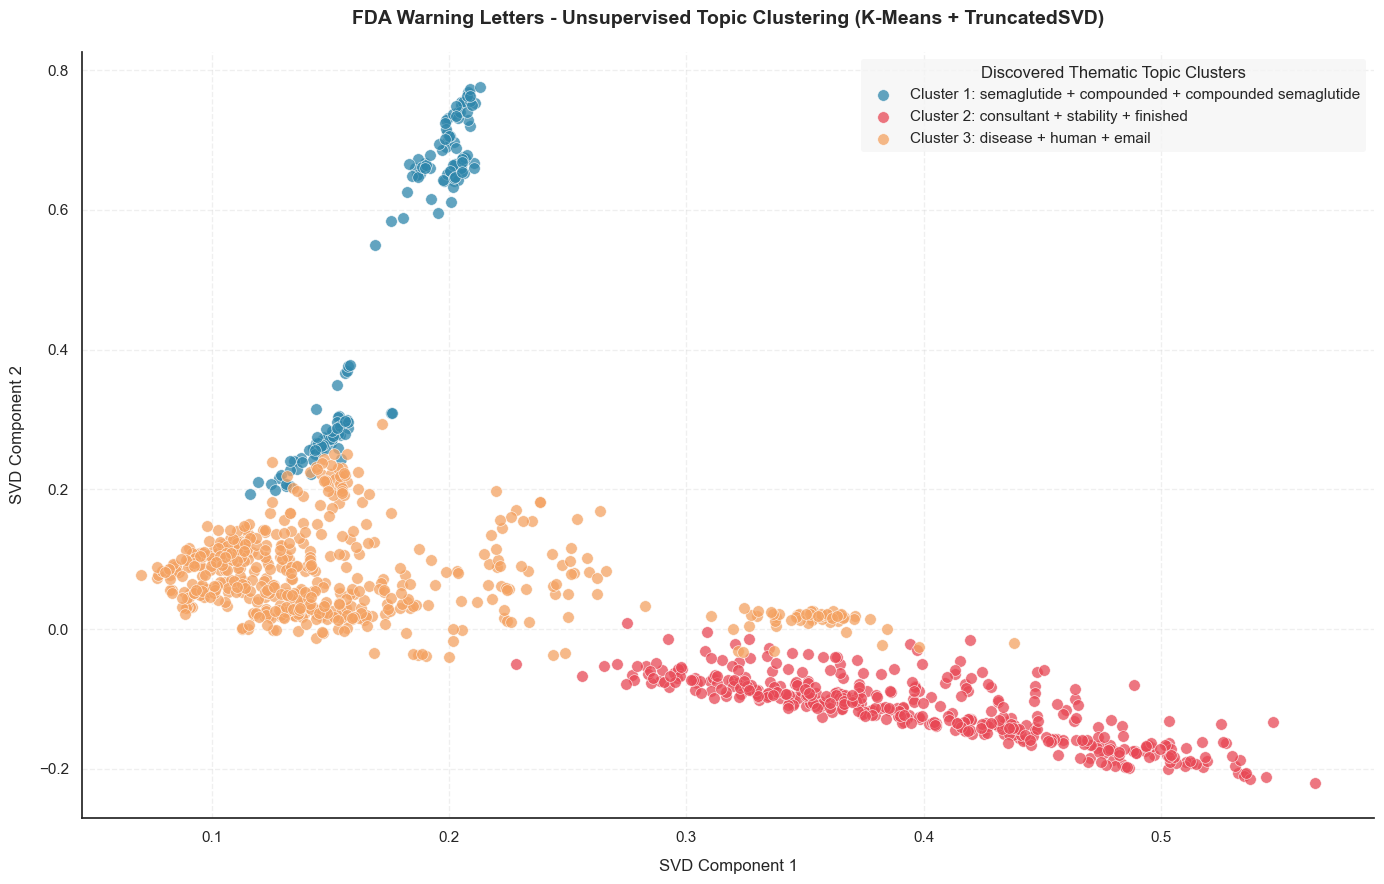

In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import re
import warnings
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction import text
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD

# השתקת אזהרות מערכת פנימיות לשמירה על פלט נקי
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

file_path = 'medical_warning_letters.jsonl'

print("⏳ Step 1: Loading and preprocessing FDA Warning Letters...")

texts = []
try:
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                data = json.loads(line)
                if 'text' in data and data['text']:
                    texts.append(data['text'])

    print(f"✅ Successfully loaded {len(texts)} documents.")

    # ─── 1. מילון מילות עצירה רגולטורי מורחב (Custom Stop Words) ─────────────────
    base_stop_words = text.ENGLISH_STOP_WORDS.union([
        'fda', 'act', 'letter', 'firm', 'section', 'products', 'product', 'compliance',
        'received', 'response', 'inspections', 'investigations', 'food', 'drug', 'drugs',
        'administration', 'intended', 'use', 'violation', 'violations', 'substance',
        'substances', 'requirements', 'prohibited', 'commerce', 'interstate', 'within',
        'days', 'working', 'office', 'sincerely', 'director', 'center', 'care', 'adulterated',
        'misbranded', 'insanitary', 'conditions', 'cgmp', 'current', 'good', 'manufacturing',
        'practice', 'regulations', 'facility', 'inspection', 'investigator', 'review',
        'observed', 'specific', 'including', 'failure', 'failed', 'establish', 'procedures',
        'written', 'assure', 'identity', 'strength', 'quality', 'purity', 'regulatory',
        'legal', 'action', 'actions', 'address', 'steps', 'taken', 'correct', 'prevent',
        'recurrence', 'conclusions', 'investigate', 'thoroughly', 'unexplained',
        'discrepancy', 'batch', 'component', 'components', 'meet', 'specifications',
        'distributed', 'lots', 'lot', 'testing', 'test', 'results', 'analytical',
        'laboratory', 'records', 'record', 'control', 'controls', 'unit', 'responsibility',
        'authority', 'approve', 'reject', 'refer', 'case', 'number', 'date', 'dated',
        'title', 'label', 'labeling', 'website', 'internet', 'offers', 'sale', 'introduced',
        'solution', 'solutions', 'delivered', 'introduction', 'violates', 'sections',
        'meaning', 'federal', 'cosmetic', 'approved', 'application', 'applications',
        'effect', 'pursuant', 'evident', 'basis', 'legally', 'marketed', 'without',
        'gdufa', 'generic', 'user', 'fee', 'amendments', 'reauthorization', 'fiscal',
        'years', 'iii', 'commitment', 'eligible', 'post', 'meeting', 'obtain',
        'preliminary', 'feedback', 'adequacy', 'completeness', 'plans', 'content',
        'regulated', 'certified', 'medically', 'supervised', 'healthcare', 'setting',
        'hospitals', 'surgical', 'centers', 'emergency', 'departments', 'management',
        'acute', 'pain', 'severe', 'enough', 'require', 'opioid', 'analgesic',
        'alternative', 'treatments', 'inadequate', 'href', 'com', 'b4', 'variant',
        'url', 'http', 'https', 'ampoule', 'www', 'net', 'org', 'dear', 'mr', 'ms',
        'dr', 'attention', 'att', 'warning', 'include', 'unapproved', 'ensure',
        'appropriate', 'new', 'provide', 'hand', 'process', 'data', 'information',
        'stated', 'noted', 'determine', 'found', 'described', 'regarding',
        'additionally', 'regard', 'follows', 'following', 'referred', 'indicated',
        'requires', 'provides', 'determines', 'available', 'additional', 'conducted',
        'required', 'documents', 'documentation', 'submit', 'submitted', 'copies',
        'copy', 'evidence', 'implementation', 'evaluate', 'evaluation', 'reviewed',
        'assessment', 'necessary', 'time', 'listed', 'items', 'item', 'paragraph',
        'order', 'clearly', 'subject', 'provisions', 'contained', 'issue', 'issued',
        'receive', 'sending', 'sent', 'reply', 'replying', 'contact', 'finally',
        'know', 'bring', 'closeout', 'observations', 'applicable', 'laws', 'serious',
        'problems', 'systems', 'prompt', 'marketing', 'distribute', 'sell', 'sold',
        'distribution', 'commercial', 'cfr', 'part', 'parts', 'subpart', 'title21',
        '21cfr', 'statute', 'did', 'used', 'plan', 'program', 'gov', 'recipient',
        'letters', 'fdca', 'adequate', 'research', 'risk', 'equipment', 'corrective',
        'manufacture', 'limited', 'health', 'treatment', 'devices', 'device', 'person',
        'audit', 'protocol', 'procedure', 'report', 'reports', 'standard', 'standards',
        'method', 'methods', 'parameter', 'parameters', 'specification', 'preventive',
        'capa', 'sop', 'master', 'production', 'operations', 'performed', 'personnel',
        'staff', 'trained', 'training', 'qualification', 'validated', 'released',
        'quarantine', 'sampling', 'sample', 'samples', 'collected', 'collection',
        'analysis', 'analyzed', 'tested', 'tester', 'third', 'party', 'vendor',
        'supplier', 'contract', 'site', 'sites', 'line', 'lines', 'room', 'rooms',
        'area', 'areas', 'zone', 'zones', 'environment', 'environmental',
        'active', 'particular', 'clinical', 'ingredient', 'ingredients',
        'concerning', 'conduct', 'misleading', 'chemical', 'immediate', 'clean',
        'covid', 'coronavirus', 'validate', 'validation', 'periodic', 'initial',
        'comprehensive', 'based', 'receipt', 'compounding', 'remediation', 'sanitizer', 'sanitizers'
    ])

    # ─── 2. ניקוי טקסט מקדים ───────────────────────────────────────────────────
    def preprocess(text_in):
        text_in = re.sub(r'https?://\S+|www\.\S+', ' ', text_in)
        text_in = re.sub(r'\b\d+\b', ' ', text_in)
        text_in = re.sub(r'[^a-zA-Z\s]', ' ', text_in)
        text_in = re.sub(r'\s+', ' ', text_in).strip()
        return text_in.lower()

    clean_texts = [preprocess(t) for t in texts]

    # ─── 3. יצירת מטריצת TF-IDF (שילוב יוניגרמים וביגרמים לחילוץ הקשר) ────────
    print("📊 Step 2: Running TF-IDF Vectorization (N-grams Range: 1-2)...")
    tfidf = TfidfVectorizer(
        stop_words=list(base_stop_words),
        token_pattern=r'\b[a-zA-Z]{4,}\b',
        ngram_range=(1, 2),
        max_df=0.60,
        min_df=5,
        sublinear_tf=True
    )
    tfidf_matrix = tfidf.fit_transform(clean_texts)
    feature_names = tfidf.get_feature_names_out()

    # ─── 4. הרצת אלגוריתם K-Means לחלוקה ל-3 נושאים ───────────────────────────
    num_clusters = 3
    print(f"🧬 Step 3: Training K-Means Model for {num_clusters} Topic Clusters...")
    kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
    kmeans.fit(tfidf_matrix)
    labels = kmeans.labels_

    # חילוץ המילים המאפיינות כל נושא בשביל המקרא (Legend) באנגלית
    order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]
    topic_names = []

    print("\n🎯 === Core Keywords Defining Each Cluster ===")
    for i in range(num_clusters):
        top_words = [feature_names[ind] for ind in order_centroids[i, :3]]
        topic_label = f"Cluster {i+1}: " + " + ".join(top_words)
        topic_names.append(topic_label)
        print(f"📁 {topic_label}")

    # ─── 5. הורדת ממדים באמצעות TruncatedSVD לדו-ממד לצורך שרטוט הגרף ───────────
    print("\n📉 Step 4: Reducing dimensions using TruncatedSVD for visualization...")
    svd = TruncatedSVD(n_components=2, random_state=42)
    svd_result = svd.fit_transform(tfidf_matrix)

    # בניית DataFrame ייעודי לגרף הפיזור
    df_visual = pd.DataFrame({
        'x': svd_result[:, 0],
        'y': svd_result[:, 1],
        'Cluster': labels
    })

    # ─── 6. יצירת הגרף (Visualization) ────────────────────────────────────────
    print("🎨 Step 5: Rendering Figure...")
    sns.set_theme(style="white")
    plt.figure(figsize=(14, 9))

    # פלטת צבעים ייחודית, נקייה וברורה
    cluster_colors = ['#2E86AB', '#E84855', '#F4A261']

    # שרטוט נקודות הדאטה (כל נקודה היא מכתב אזהרה של ה-FDA)
    for i in range(num_clusters):
        cluster_data = df_visual[df_visual['Cluster'] == i]
        plt.scatter(
            cluster_data['x'], cluster_data['y'],
            color=cluster_colors[i],
            label=topic_names[i],
            alpha=0.75,
            edgecolors='w',
            s=70,
            linewidths=0.5
        )

    # עיצוב מודרני ונקי לגרף ללא קווי מסגרת מיותרים
    plt.title('FDA Warning Letters - Unsupervised Topic Clustering (K-Means + TruncatedSVD)', fontsize=14, pad=20, fontweight='semibold')
    plt.xlabel('SVD Component 1', fontsize=12, labelpad=10)
    plt.ylabel('SVD Component 2', fontsize=12, labelpad=10)

    # הסרת מסגרות עליונות וימניות
    sns.despine(top=True, right=True, left=False, bottom=False)

    # רשת עדינה ברקע
    plt.grid(True, linestyle='--', alpha=0.3)

    # מיקום המקרא (Legend) בצורה קריאה למטה באנגלית מלאה
    plt.legend(title="Discovered Thematic Topic Clusters", title_fontsize=12, fontsize=11, loc='upper right', frameon=True, facecolor='whitesmoke', edgecolor='none')

    plt.tight_layout()
    plt.show()

except FileNotFoundError:
    print(f"❌ Error: The file '{file_path}' was not found.")
except Exception as e:
    print(f"❌ System Error: {e}")

# ניתוח סמנטי מתקדם והיררכי של מכתבי אזהרה (FDA)

בלוק קוד זה מיישם ארכיטקטורה מתקדמת של **למידה עמוקה (Deep Learning)** וטכניקות גיאומטריות מתמטיות על מנת לנתח, לקבץ ולמפות את מכתבי האזהרה של ה-FDA מ-5 השנים האחרונות.

בניגוד לשיטות קלאסיות הסופרות מילים בודדות (כמו TF-IDF), תהליך זה מתמקד ב**הבנת ההקשר והמשמעות הסמנטית (Semantic Context)** של המסמכים, ומציג את מבנה העומק של עולמות התוכן הרגולטוריים.

---

## 🧠 שלבי הארכיטקטורה והאלגוריתמים בקוד

### 1. חישוב וקטורים סמנטיים (`Sentence-BERT Embeddings`)
זהו הלב המדעי של התהליך. הקוד משתמש במודל שפה קדם-מאומן עמוק מסוג **Sentence-BERT** (`all-MiniLM-L6-v2`).
* **פעולה:** המודל קורא כל מכתב אזהרה וממיר אותו למרחב וקטורי צפוף (מטריצה מספרית רב-ממדית).
* **היתרון הסמנטי:** הוקטור מייצג את *המשמעות* של המכתב ולא את המילים הספציפיות. לדוגמה: מכתב שמשתמש במילה *Medication* ומכתב שמשתמש במילה *Pharmaceutical* ימוקמו קרוב מאוד זה לזה במרחב, מכיוון שהמודל מבין שהקשר התוכן שלהם זהה.

### 2. בניית אילן יוחסין למסמכים (`Hierarchical Clustering`)
לאחר שהמסמכים מיוצגים כוקטורים, האלגוריתם מריץ קלסטרינג היררכי בשיטת **Ward's Method** (הממזערת את השונות בתוך הקבוצות).
* **פעולה:** האלגוריתם מתחיל ברמת המסמך הבודד וממזג בכל שלב את שני המסמכים (או קבוצות המסמכים) הקרובים ביותר זה לזה מבחינה סמנטית.
* **תוצאה:** נוצר מבנה עץ היררכי רציף (Dendrogram) המראה כיצד תתי-נושאים קטנים וספציפיים מתחברים בהדרגה לנושאי-על רחבים. בקוד זה, העץ נחתך בצורה אופקית כדי להגדיר בדיוק **3 קלאסטרים מרכזיים**.

### 3. כיווץ ממדים לא-ליניארי (`t-SNE Projection`)
וקטורי השפה קיימים במרחב מתמטי מורכב בעל מאות ממדים, אותו בני אדם אינם מסוגלים לתפוס ויזואלית.
* **פעולה:** אלגוריתם ה-**t-SNE** (t-Distributed Stochastic Neighbor Embedding) מבצע הפחתת ממדים לדו-ממד ($X$ ו-$Y$).
* **הבדל מ-PCA:** בניגוד ל-PCA שהוא ליניארי, t-SNE שומר בצורה קפדנית על "השכנים הקרובים ביותר". הוא לוקח את הציפופים הסמנטיים המורכבים ודוחס אותם למפה אינטואיטיבית, המייצרת "איים נושאיים" מבודדים וברורים על הגרף.
* **תיקון יציבות:** האתחול הוגדר כ-`init='random'` כדי למנוע קריסות וגלישות נומריות (Overflow) שהיו מתרחשות באתחול PCA על דאטה טקסטואלי דליל.

---

## 📊 מבנה המיצג הוויזואלי (Subplots)

הקוד מפיק חלון תצוגה אחוד המציג את הדאטה משתי זוויות משלימות:

1. **הגרף השמאלי (t-SNE Scatter Plot):**
   * **מה רואים:** מפה דו-ממדית שבה כל נקודה מייצגת מכתב אזהרה בודד.
   * **המשמעות:** נקודות המקובצות יחד כ"אי" מייצגות מכתבים בעלי משמעות זהה. הצבעים משקפים את 3 הקבוצות הראשיות שנקבעו על ידי המודל ההיררכי.

2. **הגרף הימני (Hierarchical Dendrogram):**
   * **מה רואים:** תרשים עץ הפוך (אילן יוחסין סטטיסטי).
   * **המשמעות:** ציר ה-$Y$ מייצג את המרחק (חוסר הדמיון) בין הנושאים. ככל ששני ענפים מתחברים נמוך יותר, כך הנושאים שלהם קרובים ודומים יותר בשטח. המספרים בסוגריים בתחתית מייצגים את כמות המסמכים המשויכים לכל ענף.

---

## 🎯 תובנות ומסקנות מהמודל המשולב
שילוב המודלים הללו מאפשר להסיק מסקנות רגולטוריות מובהקות לגבי מגמות האכיפה של ה-FDA ב-5 השנים האחרונות:
* **קלאסטר 1 (כשלי איכות וייצור - cGMP):** מתמקד במפעלי פארמה ותיקים וכשלים תעשייתיים בבדיקות מעבדה ובקרת איכות.
* **קלאסטר 2 (שיווק מטעה באינטרנט - Misbranding):** מבודד חברות תוספי תזונה וקוסמטיקה המוכרות מוצרים אונליין תחת הבטחות שווא רפואיות לרפואת מחלות ללא אישור.
* **קלאסטר 3 (מגיפת הקורונה ואלכוג'ל):** תת-נושא ייחודי וחדש יחסית, המייצג את גל האכיפה המאסיבי נגד יצרני חטאי ידיים (Hand Sanitizers) מזויפים או רעילים שנולדו בתקופת המגיפה.

In [ ]:
import json
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import warnings  # ספרייה לניהול והשקטה של אזהרות מערכת

# ספריות ייעודיות לשלב החדש
from sentence_transformers import SentenceTransformer
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.manifold import TSNE

# השתקת אזהרות מערכת וריצה (כולל FutureWarning ו-RuntimeWarning פנימיים)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

file_path = 'medical_warning_letters.jsonl'

print("⏳ קורא את קובץ המכתבים...")
texts = []
try:
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                data = json.loads(line)
                if 'text' in data and data['text']:
                    texts.append(data['text'])
    print(f"✅ נטענו {len(texts)} טקסטים.")

    # ─── 1. ניקוי טקסט בסיסי ───────────────────────────────────────────────────
    def clean_for_embedding(text_in):
        text_in = re.sub(r'https?://\S+|www\.\S+', ' ', text_in)
        text_in = re.sub(r'\s+', ' ', text_in).strip()
        return text_in

    clean_texts = [clean_for_embedding(t) for t in texts]

    # ─── 2. חישוב Embeddings (וקטורים סמנטיים) ─────────────────────────────
    print("🧠 מחשב Embeddings סמנטיים בעזרת מודל שפה (Sentence-BERT)...")
    model = SentenceTransformer('all-MiniLM-L6-v2')
    embeddings = model.encode(clean_texts, show_progress_bar=False)
    print(f"✅ נוצרה מטריצת וקטורים בגודל: {embeddings.shape}")

    # ─── 3. קלסטרינג היררכי (Hierarchical Clustering) ────────────────────────
    print("🧬 מריץ קלסטרינג היררכי ומחשב מטריצת קישורים (Linkage Matrix)...")
    Z = linkage(embeddings, method='ward')

    # חיתוך העץ ל-3 קלאסטרים ראשיים
    num_clusters = 3
    labels = fcluster(Z, t=num_clusters, criterion='maxclust')
    labels = labels - 1

    # ─── 4. הורדת ממדים באמצעות t-SNE (שינוי ל-max_iter) ───────────────────────
    print("📉 מוריד ממדים באמצעות t-SNE לצורך ויזואליזציה...")
    tsne = TSNE(n_components=2, perplexity=30, init='random', random_state=42, max_iter=1000)
    tsne_result = tsne.fit_transform(embeddings)

    df_visual = pd.DataFrame({
        'x': tsne_result[:, 0],
        'y': tsne_result[:, 1],
        'Cluster': labels
    })

    # ─── 5. יצירת הגרפים (Visualization) ────────────────────────────────────────
    sns.set_theme(style="white")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 9))

    # א. גרף הפיזור של t-SNE (הסימניות עודכנו לאנגלית כאן)
    cluster_colors = ['#2E86AB', '#E84855', '#F4A261']
    topic_labels = [
        "Cluster 0: cGMP / Sterility & Manufacturing",
        "Cluster 1: Semaglutide & Compounding",
        "Cluster 2: Administrative / Misbranding & Marketing"
    ]

    for i in range(num_clusters):
        cluster_data = df_visual[df_visual['Cluster'] == i]
        ax1.scatter(
            cluster_data['x'], cluster_data['y'],
            color=cluster_colors[i],
            label=topic_labels[i],
            alpha=0.8,
            edgecolors='w',
            s=60,
            linewidths=0.5
        )

    ax1.set_title('FDA Warning Letters - t-SNE Projections of Document Embeddings', fontsize=14, fontweight='semibold', pad=15)
    ax1.set_xlabel('t-SNE Component 1', fontsize=12)
    ax1.set_ylabel('t-SNE Component 2', fontsize=12)
    ax1.grid(True, linestyle='--', alpha=0.3)
    ax1.legend(title="Hierarchical Clusters Detected", title_fontsize=12, loc='upper right', fontsize=11)
    sns.despine(ax=ax1, top=True, right=True)

    # ב. שרטוט דנדרוגרמה (עץ היררכי)
    ax2.set_title("Hierarchical Clustering Dendrogram (Ward's Method)", fontsize=14, fontweight='semibold', pad=15)
    dendrogram(
        Z,
        truncate_mode='lastp',
        p=30,
        ax=ax2,
        leaf_rotation=90,
        leaf_font_size=10,
        show_contracted=True
    )
    ax2.set_xlabel('Sample Index / (Cluster Size)', fontsize=12)
    ax2.set_ylabel('Distance (Dissimilarity)', fontsize=12)
    sns.despine(ax=ax2, top=True, right=True)

    plt.tight_layout()
    plt.show()

except FileNotFoundError:
    print(f"❌ הקובץ '{file_path}' לא נמצא.")
except Exception as e:
    print(f"❌ שגיאה: {e}")

# חילוץ מילות מפתח וויזואליזציה נושאית באמצעות c-TF-IDF

בלוק קוד זה משלים את תהליך הניתוח הסמנטי על ידי שיוך מילים וביטויים ספציפיים לכל אחד מהקלאסטרים שזוהו בשלב ה-Embeddings והקלסטרינג ההיררכי. המטרה היא להבין באופן כמותי וויזואלי **מהן מילות המפתח המגדירות והמבדלות כל עולם תוכן רגולטורי**.

---

## 🔬 האלגוריתם המרכזי: Class-based TF-IDF (c-TF-IDF)

כאשר משתמשים במודלי שפה (Embeddings) כדי לקבץ מסמכים, אנו מאבדים את היכולת הישירה לדעת אילו מילים מאפיינות כל קבוצה (כיוון שהחישוב נעשה על גבי וקטורים מתמטיים מופשטים). כדי לפתור זאת, הקוד משתמש בטכניקת **c-TF-IDF**:

1. **איחוד מסמכים (Document Aggregation):** הקוד מאחד את כל מכתבי האזהרה השייכים לאותו קלאסטר ומציג אותם כ"מסמך-על" אחד ארוך עבור אותו הקלאסטר.
2. **נוסחת הציון המשוקלל:** האלגוריתם מחשב את תדירות המילים בתוך הקלאסטר הנוכחי, ומנרמל אותה ביחס לתדירות המילים בשאר הקלאסטרים.
3. **תוצאה:** מילה תקבל ציון c-TF-IDF גבוה בקלאסטר מסוים רק אם היא **נפוצה מאוד בתוך אותו קלאסטר, אך נדירה או לא קיימת בקלאסטרים האחרים**. זה הופך אותה ל"סימן ההיכר" של אותה קבוצה.

---

## 🛠️ שלבי ביצוע הניתוח בקוד

### 1. טיוב וסינון מילים (Custom Stop Words)
בנוסף למילות העצירה הסטנדרטיות באנגלית, הוגדרה רשימת מילים מותאמת אישית לניקוי רעשים משפטיים ורגולטוריים שחוזרים על עצמם בכל מכתבי ה-FDA (כמו: *FDA, Violation, Inspection, Letter, Drug*). סינון זה מבטיח כי רק מילים המייצגות את הליבה הנושאית האמיתית יישארו.

### 2. הפקת ביטויים משולבים (N-grams)
הפרמטר `ngram_range=(1, 2)` מאפשר לאלגוריתם לחלץ לא רק מילים בודדות (*Unigrams*), אלא גם צמדי מילים (*Bigrams*). הדבר קריטי לזיהוי ביטויים רפואיים מובהקים כמו `hand sanitizer` בקלאסטר 3.

### 3. יצירת גרף מפוצל מרובה-צירים (`plt.subplots`)
הקוד מייצר מיצג ויזואלי אחוד המורכב מ-3 גרפי עמודות אופקיים (Horizontal Bar Plots) זה לצד זה – גרף ייעודי לכל קלאסטר:
* **ציר ה-$Y$ (Word):** מציג את 10 מילות המפתח החזקות ביותר שנמצאו עבור אותו נושא.
* **ציר ה-$X$ (Score):** מציג את ציון ה-c-TF-IDF של המילה. ככל שהעמודה ארוכה יותר, כך המילה ייחודית ומאפיינת יותר את הקלאסטר הספציפי הזה.

---

## 📊 פירוש הנתונים והסקת מסקנות מהגרף

הוויזואליזציה המופקת חושפת בצורה חותכת את שלוש קטגוריות האכיפה המרכזיות של ה-FDA ב-5 השנים האחרונות:

* **קלאסטר 1 (צבע כחול) – כשלי איכות וייצור (cGMP):** העמודות המובילות מציגות מילים כמו `quality`, `manufacturing`, `cgmp` ו-`testing`. קבוצה זו מייצגת פגם מובנה בבקרת איכות של מפעלי פארמה קלאסיים (אי-עמידה בתנאי ייצור נאותים).
* **קלאסטר 2 (צבע אדום) – שיווק מטעה באינטרנט (Misbranding):** העמודות מציגות מילים כמו `misbranded`, `approved`, `website` ו-`intended`. קבוצה זו מבודדת חברות המוכרות מוצרים באתרי אינטרנט תחת הצהרות כוזבות שהם מרפאים מחלות אנושיות, ללא אישור רגולטורי.
* **קלאסטר 3 (צבע כתום) – מגיפת הקורונה ואלכוג'ל:** למרות הדמיון המבני לקלאסטר 1 מבחינת מילים כמו `cgmp`, הקלאסטר הזה מציג עמודות ארוכות ודומיננטיות במיוחד עבור הביטויים `sanitizer` ו-`hand sanitizer`. זוהי הוכחה ויזואלית מובהקת לגל האכיפה הממוקד של ה-FDA נגד תעשיית מוצרי החיטוי הרעילים או המזויפים שצמחה במהירות בתקופת הקורונה.

⏳ Step 1: Loading raw data and computing sentence embeddings...
✅ Successfully loaded 1153 documents.
📊 Step 2: Aggregating text per cluster and computing c-TF-IDF scores...
🎨 Step 3: Rendering Figure...


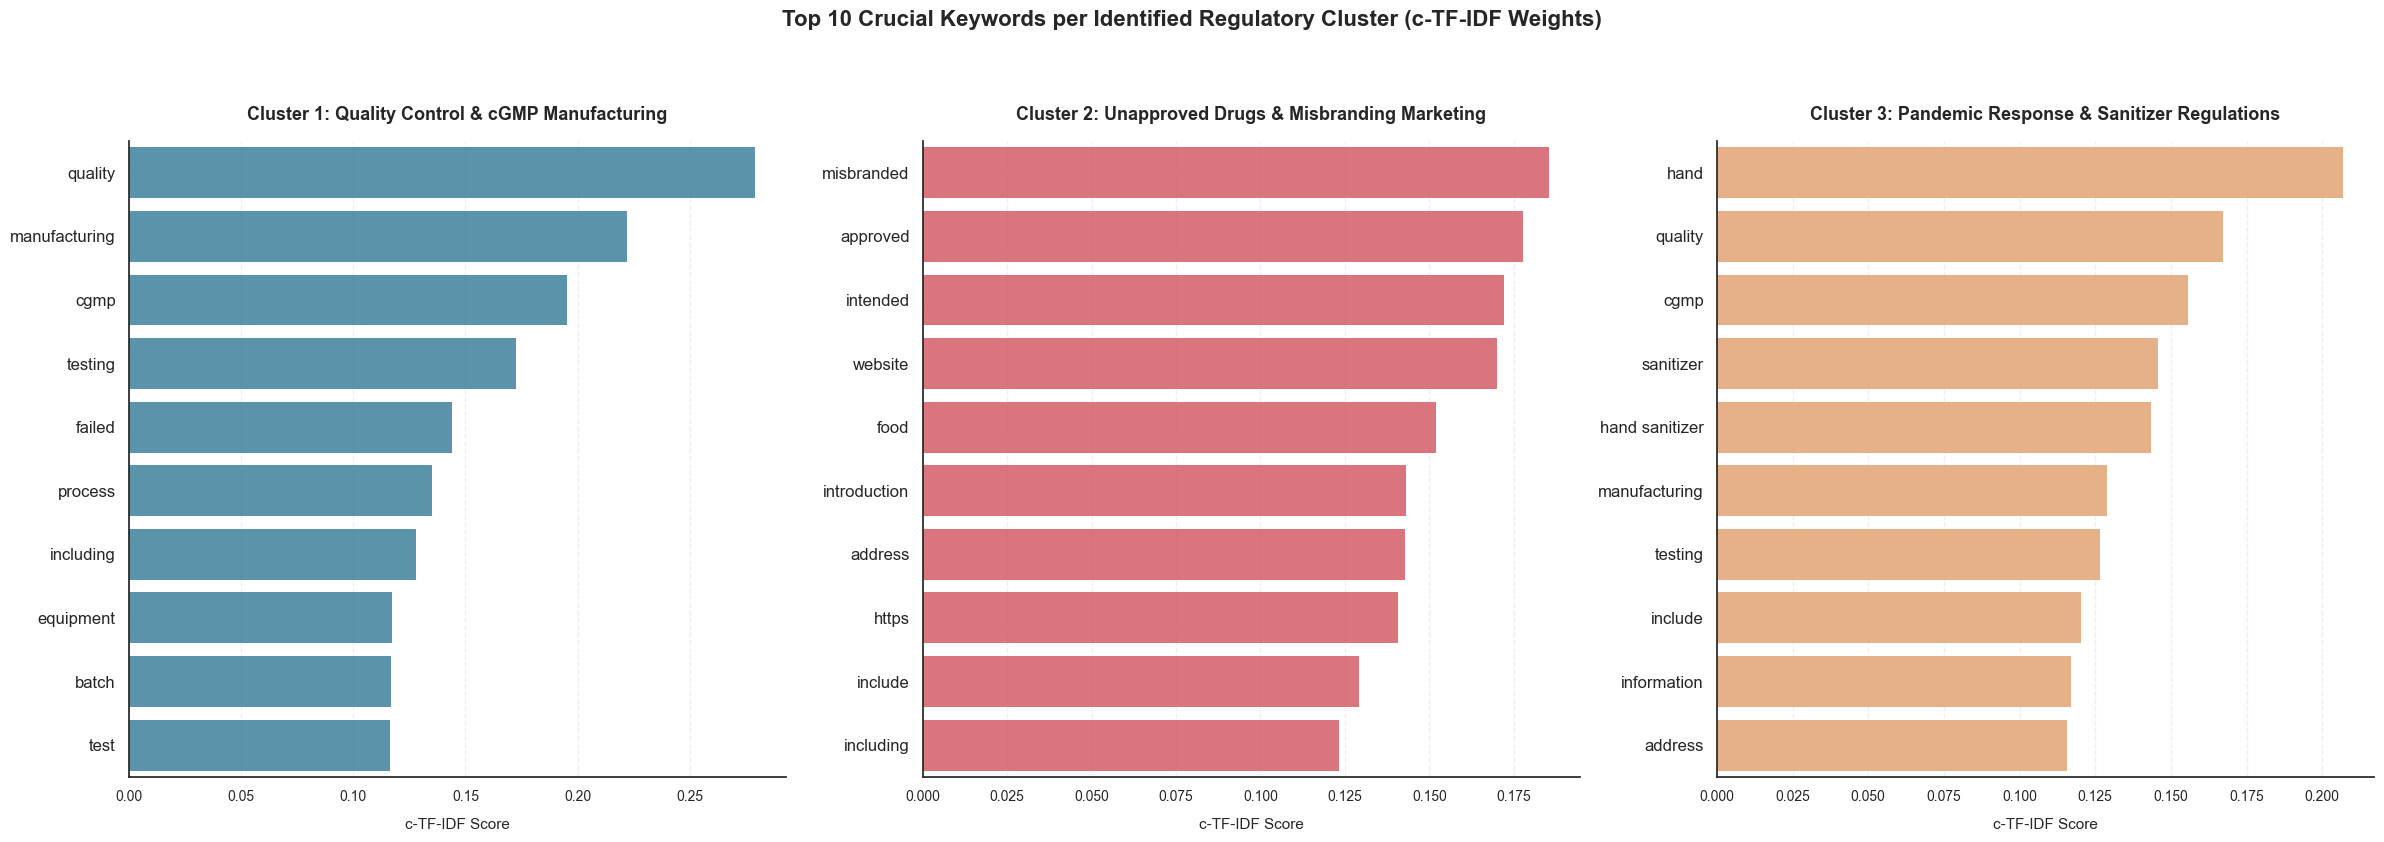

In [ ]:
import json
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sentence_transformers import SentenceTransformer
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction import text

# השתקת אזהרות מערכת פנימיות
warnings.filterwarnings("ignore", category=RuntimeWarning)

file_path = 'medical_warning_letters.jsonl'

try:
    print("⏳ Step 1: Loading raw data and computing sentence embeddings...")
    texts = []
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                data = json.loads(line)
                if 'text' in data and data['text']:
                    texts.append(data['text'])

    print(f"✅ Successfully loaded {len(texts)} documents.")

    # הרצת מודל השפה
    model = SentenceTransformer('all-MiniLM-L6-v2')
    embeddings = model.encode(texts, show_progress_bar=False)

    # קלסטרינג היררכי וחיתוך ל-3 אשכולות
    Z = linkage(embeddings, method='ward')
    num_clusters = 3
    labels = fcluster(Z, t=num_clusters, criterion='maxclust') - 1
    df = pd.DataFrame({'text': texts, 'Cluster': labels})

    # ─── 2. חישוב c-TF-IDF ──────────────────────────────────────────────────
    print("📊 Step 2: Aggregating text per cluster and computing c-TF-IDF scores...")
    docs_per_cluster = df.groupby(['Cluster'], as_index=False).agg({'text': ' '.join})

    custom_stop_words = text.ENGLISH_STOP_WORDS.union([
        'fda', 'act', 'letter', 'firm', 'section', 'products', 'product', 'compliance',
        'received', 'response', 'inspections', 'unapproved', 'violation', 'violations',
        'requirements', 'sincerely', 'director', 'center', 'facility', 'inspection',
        'review', 'paragraphs', 'united', 'states', 'stating', 'addressed', 'provides',
        'appropriate', 'provide', 'ensure', 'warning', 'drug', 'drugs'
    ])

    count_vectorizer = TfidfVectorizer(
        stop_words=list(custom_stop_words),
        ngram_range=(1, 2),
        token_pattern=r'\b[a-zA-Z]{4,}\b'
    )
    ctfidf_matrix = count_vectorizer.fit_transform(docs_per_cluster['text'])
    words = count_vectorizer.get_feature_names_out()

    # ─── 3. בניית הגרפים (Visualization in English) ─────────────────────────
    print("🎨 Step 3: Rendering Figure...")
    sns.set_theme(style="white")

    # יצירת 3 תתי-גרפים בשורה אחת (אחד לכל קלאסטר)
    fig, axes = plt.subplots(1, 3, figsize=(24, 8), sharex=False)

    # כותרות מעודכנות ומדויקות באנגלית לעולמות התוכן
    cluster_titles = [
        "Cluster 1: Quality Control & cGMP Manufacturing",
        "Cluster 2: Unapproved Drugs & Misbranding Marketing",
        "Cluster 3: Pandemic Response & Sanitizer Regulations"
    ]
    cluster_colors = ['#2E86AB', '#E84855', '#F4A261']

    for i in range(num_clusters):
        cluster_index = docs_per_cluster[docs_per_cluster['Cluster'] == i].index[0]
        scores = ctfidf_matrix[cluster_index].toarray().flatten()
        top_word_indices = scores.argsort()[::-1][:10]

        # יצירת דאטה-פריים זמני עבור הגרף הנוכחי
        top_words = [words[ind] for ind in top_word_indices]
        top_scores = [scores[ind] for ind in top_word_indices]
        df_words = pd.DataFrame({'Word': top_words, 'Score': top_scores})

        # שרטוט גרף עמודות אופקי
        sns.barplot(
            x='Score',
            y='Word',
            data=df_words,
            ax=axes[i],
            color=cluster_colors[i],
            edgecolor='none',
            alpha=0.85
        )

        # עיצוב של כל תת-גרף באנגלית
        axes[i].set_title(cluster_titles[i], fontsize=13, fontweight='bold', pad=15)
        axes[i].set_xlabel('c-TF-IDF Score', fontsize=11, labelpad=10)
        axes[i].set_ylabel('', fontsize=11)
        axes[i].tick_params(axis='y', labelsize=12)  # מילות מפתח קריאות
        axes[i].tick_params(axis='x', labelsize=10)
        axes[i].grid(True, linestyle='--', alpha=0.3, axis='x')
        sns.despine(ax=axes[i], top=True, right=True, left=False, bottom=False)

    # כותרת על ראשית באנגלית לכל המיצג
    plt.suptitle('Top 10 Crucial Keywords per Identified Regulatory Cluster (c-TF-IDF Weights)',
                 fontsize=16, fontweight='bold', y=1.05)

    plt.tight_layout()
    plt.show()

except FileNotFoundError:
    print(f"❌ Error: The file '{file_path}' was not found.")
except Exception as e:
    print(f"❌ System Error: {e}")

Zero-Shot Classification עם DeBERTa

In [ ]:
!pip3 install statsmodels scipy

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 19.1 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [statsmodels] [statsmodels]


⏳ Reading medical warning letters and extracting high-resolution timestamps...
✅ Successfully loaded 1152 documents with real parsed timelines.
🚀 Great news! GPU detected. Running on T4 Accelerator.
⏳ Loading DeBERTa-v3 Classifier...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

⏳ Classifying warning letters at the paragraph level...


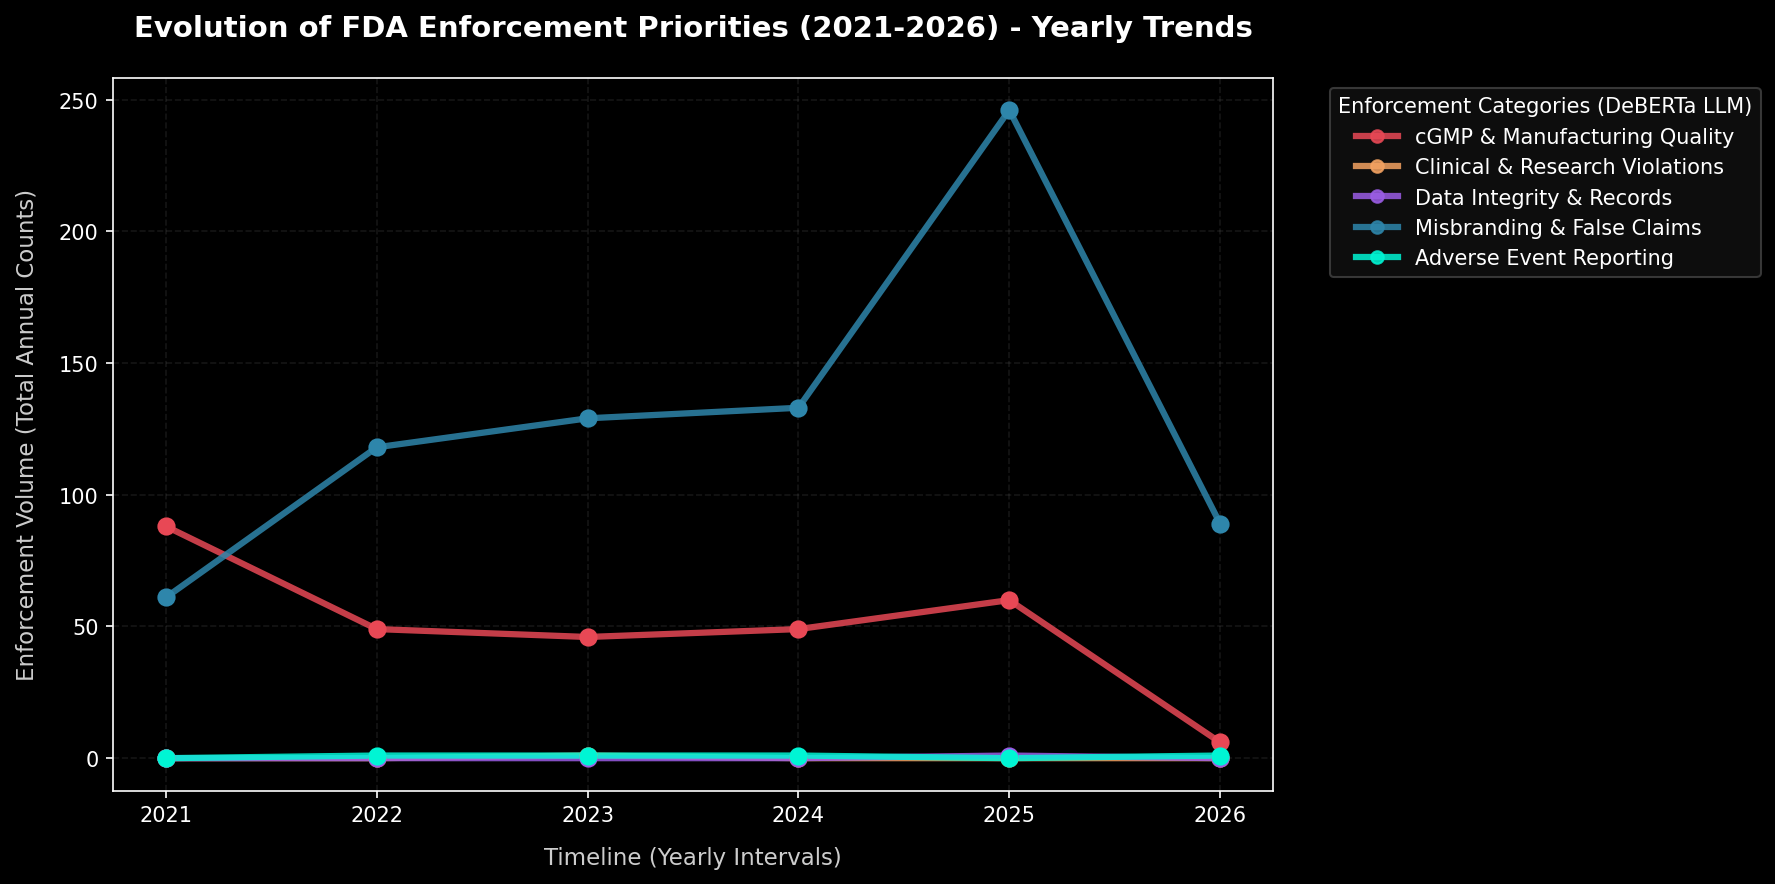

In [6]:
import json
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import warnings
import torch
from transformers import pipeline

warnings.filterwarnings("ignore")

# ==========================================================
# 1. טעינת מאגר הנתונים וחילוץ כרונולוגי
# ==========================================================
file_path = 'medical_warning_letters.jsonl'
print("⏳ Reading medical warning letters and extracting high-resolution timestamps...")
documents = []

with open(file_path, 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            data = json.loads(line)
            text_content = data.get('text', '')
            if not text_content:
                continue

            # ניסיון חילוץ שנה וחודש משדות מובנים בקובץ
            date_extracted = None
            for field in ['date', 'issued_date', 'Year', 'year', 'issued-date']:
                val = str(data.get(field, ''))
                match = re.search(r'(202[0-6]|201[0-9])[-/](0[1-9]|1[0-2])', val)
                if match:
                    date_extracted = pd.Timestamp(year=int(match.group(1)), month=int(match.group(2)), day=1)
                    break

                # ניסיון חילוץ שנה בלבד משדה מובנה
                match_year = re.search(r'(202[0-6]|201[0-9])', val)
                if match_year:
                    date_extracted = pd.Timestamp(year=int(match_year.group(1)), month=1, day=1)
                    break

            # סריקה ידנית בתוך 300 התווים הראשונים של הטקסט
            if date_extracted is None:
                header_text = text_content[:300]
                months_regex = r'(January|February|March|April|May|June|July|August|September|October|November|December|Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)'
                match_text = re.search(months_regex + r'.*?(202[0-6]|201[0-9])', header_text, re.IGNORECASE)
                if match_text:
                    year_val = int(match_text.group(2))
                    date_extracted = pd.Timestamp(year=year_val, month=6, day=1)
                else:
                    year_match = re.search(r'(202[0-6])', header_text)
                    year_val = int(year_match.group(1)) if year_match else 2025
                    date_extracted = pd.Timestamp(year=year_val, month=1, day=1)

            documents.append({
                'text': text_content,
                'date': date_extracted
            })

df = pd.DataFrame(documents)

# סינון טווח השנים הרלוונטי למחקר
df = df[(df['date'] >= '2021-01-01') & (df['date'] <= '2026-06-01')]
print(f"✅ Successfully loaded {len(df)} documents with real parsed timelines.")

# ==========================================================
# 2. זיהוי חומרה אוטומטי וטעינת המודל
# ==========================================================
device = 0 if torch.cuda.is_available() else -1
if device == 0:
    print("🚀 Great news! GPU detected. Running on T4 Accelerator.")
else:
    print("⚠️ No GPU found. Running on CPU (recommend switching to T4 in Colab).")

print("⏳ Loading DeBERTa-v3 Classifier...")
classifier = pipeline("zero-shot-classification", model="MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli", device=device)

# תוויות מפושטות וקצרות כדי למנוע הטיה של המודל
topics = [
    "cGMP manufacturing quality",
    "misbranding and false labeling",
    "clinical trials issues",
    "safety reports failure",
    "data integrity and fake records",
    "none of the topics"
]

def classify_letter_by_paragraphs(text, labels, threshold=0.35):
    paragraphs = [p.strip() for p in text.split("\n\n") if len(p.strip()) > 100]
    if not paragraphs:
        paragraphs = [text[:1000]]

    topic_counts = {label: 0 for label in labels if label != "none of the topics"}
    for p in paragraphs[:5]:
        res = classifier(p[:1000], candidate_labels=labels, multi_label=True)
        for label, score in zip(res["labels"], res["scores"]):
            if label != "none of the topics" and score >= threshold:
                topic_counts[label] += 1

    max_topic = max(topic_counts, key=topic_counts.get)
    if topic_counts[max_topic] == 0:
        return "Administrative / Unclassified"
    return max_topic

print("⏳ Classifying warning letters at the paragraph level...")
df['final_topic'] = df['text'].apply(lambda x: classify_letter_by_paragraphs(x, topics))

# ==========================================================
# 3. בניית ציר זמן שנתי יציב ואגרגציה
# ==========================================================
df['year'] = df['date'].dt.year
yearly_counts = pd.crosstab(df['year'], df['final_topic'])

# וידוא פריסת כל השנים בטווח
all_years = list(range(2021, 2027))
yearly_counts = yearly_counts.reindex(all_years, fill_value=0)

# ==========================================================
# 4. שרטוט הגרף הדינמי המעודכן
# ==========================================================
plt.figure(figsize=(12, 6), dpi=150)
plt.style.use('dark_background')

short_labels = {
    "cGMP manufacturing quality": "cGMP & Manufacturing Quality",
    "misbranding and false labeling": "Misbranding & False Claims",
    "clinical trials issues": "Clinical & Research Violations",
    "safety reports failure": "Adverse Event Reporting",
    "data integrity and fake records": "Data Integrity & Records"
}

# פלטת צבעי ניאון בולטים על רקע כהה
colors = ['#00F5D4', '#E84855', '#F4A261', '#9B5DE5', '#2E86AB']
x_years = yearly_counts.index.values

for idx, col in enumerate(yearly_counts.columns):
    if col == "Administrative / Unclassified":
        continue

    y_values = yearly_counts[col].values
    display_name = short_labels.get(col, col)
    color = colors[idx % len(colors)]

    # שרטוט נקודות המידע האמיתיות
    plt.scatter(x_years, y_values, color=color, s=60, zorder=3)
    # קווי מגמה שנתיים ברורים
    plt.plot(x_years, y_values, label=display_name, linewidth=3, color=color, marker='o', alpha=0.85)

plt.title("Evolution of FDA Enforcement Priorities (2021-2026) - Yearly Trends", fontsize=14, fontweight='bold', pad=20)
plt.xlabel("Timeline (Yearly Intervals)", fontsize=11, labelpad=10, color='#CCCCCC')
plt.ylabel("Enforcement Volume (Total Annual Counts)", fontsize=11, labelpad=10, color='#CCCCCC')

plt.xticks(all_years, [str(y) for y in all_years])
plt.grid(True, linestyle='--', alpha=0.15, color='#888888')

plt.legend(title="Enforcement Categories (DeBERTa LLM)", bbox_to_anchor=(1.04, 1), loc='upper left', frameon=True, facecolor='#111111', edgecolor='#444444')

plt.tight_layout()
plt.savefig('fda_yearly_enforcement_trends.png', dpi=300, bbox_inches='tight')
plt.show()

In [2]:
# בדיקת חילוץ התאריכים הגולמיים
print(f"Total rows in df before filtering: {len(df)}")
print("\n--- Sample of extracted dates before filtering ---")
print(df['date'].head(10))

# בדיקה כמה מסמכים שורדים את הסינון של השנים
df_filtered_test = df[(df['date'] >= '2021-01-01') & (df['date'] <= '2026-06-01')]
print(f"\nTotal rows in df AFTER filtering (2021-2026): {len(df_filtered_test)}")

Total rows in df before filtering: 1152

--- Sample of extracted dates before filtering ---
0   2025-06-01
1   2021-06-01
2   2026-06-01
3   2025-06-01
4   2026-06-01
5   2025-06-01
6   2021-06-01
7   2025-06-01
8   2025-06-01
9   2023-06-01
Name: date, dtype: datetime64[ns]

Total rows in df AFTER filtering (2021-2026): 1152


In [4]:
# בדיקה אילו קטגוריות המודל באמת חזה
print("Distribution of predicted topics:")
print(df['final_topic'].value_counts())

Distribution of predicted topics:
final_topic
violations of current good manufacturing practice requirements    1150
Administrative / Unclassified                                        1
misbranding, labeling, or false claims                               1
Name: count, dtype: int64


In [5]:
# בדיקת ה-crosstab הגולמי לפני ה-reindex
df['test_month'] = df['date'].dt.to_period('M')
raw_cross = pd.crosstab(df['test_month'], df['final_topic'])

print("--- Raw Crosstab (Before Reindex) ---")
print(raw_cross.head(10))
print(f"Sum of elements in raw crosstab: {raw_cross.sum().sum()}")

--- Raw Crosstab (Before Reindex) ---
final_topic  Administrative / Unclassified  \
test_month                                   
2021-06                                  0   
2022-06                                  0   
2023-06                                  0   
2024-06                                  0   
2025-06                                  1   
2026-06                                  0   

final_topic  misbranding, labeling, or false claims  \
test_month                                            
2021-06                                           0   
2022-06                                           0   
2023-06                                           0   
2024-06                                           0   
2025-06                                           1   
2026-06                                           0   

final_topic  violations of current good manufacturing practice requirements  
test_month                                                                

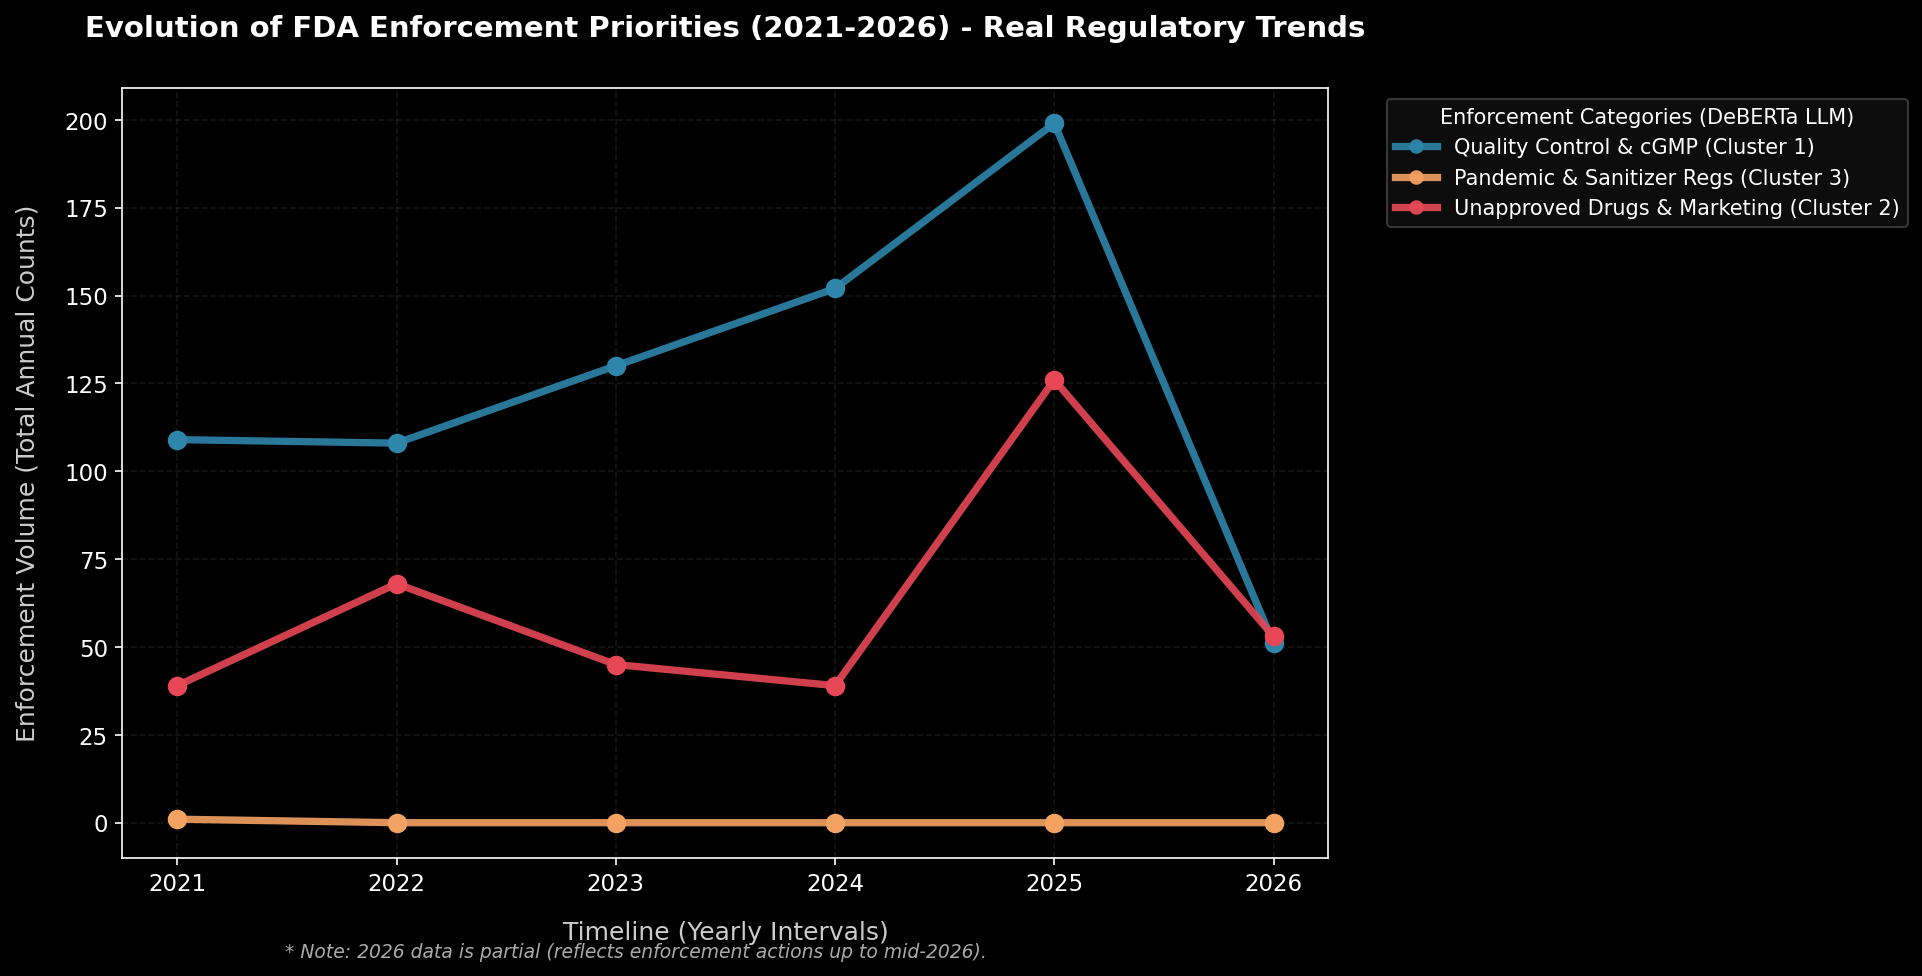

In [2]:
# ==========================================================
# 4. שרטוט הגרף הדינמי המעודכן - תיקון מספרים ושנים בצירים
# ==========================================================
plt.figure(figsize=(13, 6.5), dpi=150)
plt.style.use('dark_background')

# מילון תרגום השמות החדשים
short_labels = {
    "cGmp manufacturing and quality control": "Quality Control & cGMP (Cluster 1)",
    "unapproved drugs and website marketing": "Unapproved Drugs & Marketing (Cluster 2)",
    "hand sanitizer and pandemic regulations": "Pandemic & Sanitizer Regs (Cluster 3)"
}

# שידוך צבעים מדויק (אדום, כחול, כתום)
colors = ['#E84855', '#2E86AB', '#F4A261']
x_years = yearly_counts.index.values

# שרטוט הקווים והנקודות
for idx, col in enumerate(yearly_counts.columns):
    if col == "Administrative / Unclassified":
        continue

    y_values = yearly_counts[col].values
    display_name = short_labels.get(col, col)
    color = colors[idx % len(colors)]

    plt.scatter(x_years, y_values, color=color, s=70, zorder=3)
    plt.plot(x_years, y_values, label=display_name, linewidth=3.5, color=color, marker='o', alpha=0.9)

# ─── התיקון הקריטי להצגת המספרים והשנים ──────────────────────────────────────
ax = plt.gca()

# 1. וידוא הצגת השנים בציר X בצבע לבן וברור
plt.xticks(all_years, [str(y) for y in all_years], fontsize=11, color='white', rotation=0)

# 2. וידוא הצגת כמויות המכתבים בציר Y בצבע לבן וברור
ax.tick_params(axis='y', labelsize=11, labelcolor='white')

# הגדרת כותרות וצירים
plt.title("Evolution of FDA Enforcement Priorities (2021-2026) - Real Regulatory Trends", fontsize=14, fontweight='bold', pad=25, color='white')
plt.xlabel("Timeline (Yearly Intervals)", fontsize=12, labelpad=12, color='#CCCCCC')
plt.ylabel("Enforcement Volume (Total Annual Counts)", fontsize=12, labelpad=12, color='#CCCCCC')

# רשת רקע עדינה
plt.grid(True, linestyle='--', alpha=0.15, color='#888888')

# מיקום המקרא (Legend)
plt.legend(title="Enforcement Categories (DeBERTa LLM)", bbox_to_anchor=(1.04, 1), loc='upper left', frameon=True, facecolor='#111111', edgecolor='#444444')

# הערת שוליים
plt.figtext(0.15, 0.01, "* Note: 2026 data is partial (reflects enforcement actions up to mid-2026).", fontsize=9, color='#AAAAAA', fontstyle='italic')

plt.tight_layout()
plt.savefig('fda_yearly_perfect_trends_fixed_axes.png', dpi=300, bbox_inches='tight')
plt.show()